In [1]:
import os
import zipfile
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Unzip the dataset and rename it to Netflix_shows_movies.csv
with zipfile.ZipFile("netflix_data.zip", "r") as zip_ref:
    zip_ref.extractall()                 # unpack into the current folder

os.replace("netflix_data.csv", "Netflix_shows_movies.csv")   # replace = safe to rerun

df = pd.read_csv("Netflix_shows_movies.csv")
print(df.shape)
df.head()

(6234, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,81145628,Movie,Norm of the North: King Sized Adventure,"Richard Finn, Tim Maltby","Alan Marriott, Andrew Toth, Brian Dobson, Cole...","United States, India, South Korea, China","September 9, 2019",2019,TV-PG,90 min,"Children & Family Movies, Comedies",Before planning an awesome wedding for his gra...
1,80117401,Movie,Jandino: Whatever it Takes,NaN,Jandino Asporaat,United Kingdom,"September 9, 2016",2016,TV-MA,94 min,Stand-Up Comedy,Jandino Asporaat riffs on the challenges of ra...
2,70234439,TV Show,Transformers Prime,NaN,"Peter Cullen, Sumalee Montano, Frank Welker, J...",United States,"September 8, 2018",2013,TV-Y7-FV,1 Season,Kids' TV,"With the help of three human allies, the Autob..."
3,80058654,TV Show,Transformers: Robots in Disguise,NaN,"Will Friedle, Darren Criss, Constance Zimmer, ...",United States,"September 8, 2018",2016,TV-Y7,1 Season,Kids' TV,When a prison ship crash unleashes hundreds of...
4,80125979,Movie,#realityhigh,Fernando Lebrija,"Nesta Cooper, Kate Walsh, John Michael Higgins...",United States,"September 8, 2017",2017,TV-14,99 min,Comedies,When nerdy high schooler Dani finally attracts...


In [2]:
#looking for null values
print(df.isnull().sum())

show_id            0
type               0
title              0
director        1969
cast             570
country          476
date_added        11
release_year       0
rating            10
duration           0
listed_in          0
description        0
dtype: int64


In [3]:
# Text columns: fill blanks with "Unknown" so no titles are lost
text_cols = ["director", "cast", "country", "rating"]
df[text_cols] = df[text_cols].fillna("Unknown")

# Only 11 rows have no date_added, so dropping them loses very little
df = df.dropna(subset=["date_added"])

print(df.isnull().sum())                 # after: all zeros
df.to_csv("Netflix_shows_movies_cleaned.csv", index=False)   # cleaned copy for R

show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64


In [4]:
# Step 3: Data exploration
df.info()                                     # columns, types, non-null counts
print(df.describe(include="all"))             # summary of ALL columns, not just numbers

print("Movies vs TV shows:")
print(df["type"].value_counts(normalize=True).round(2))   # shares, e.g. 0.68 / 0.32

print("Release year - mean:", round(df["release_year"].mean()),
      "| median:", df["release_year"].median(),
      "| oldest:", df["release_year"].min(),
      "| newest:", df["release_year"].max())

<class 'pandas.DataFrame'>
RangeIndex: 6223 entries, 0 to 6222
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       6223 non-null   int64
 1   type          6223 non-null   str  
 2   title         6223 non-null   str  
 3   director      6223 non-null   str  
 4   cast          6223 non-null   str  
 5   country       6223 non-null   str  
 6   date_added    6223 non-null   str  
 7   release_year  6223 non-null   int64
 8   rating        6223 non-null   str  
 9   duration      6223 non-null   str  
 10  listed_in     6223 non-null   str  
 11  description   6223 non-null   str  
dtypes: int64(2), str(10)
memory usage: 583.5 KB
             show_id   type title director     cast        country  \
count   6.223000e+03   6223  6223     6223     6223           6223   
unique           NaN      2  6162     3302     5460            555   
top              NaN  Movie  Love  Unknown  Unknown  United States   
f

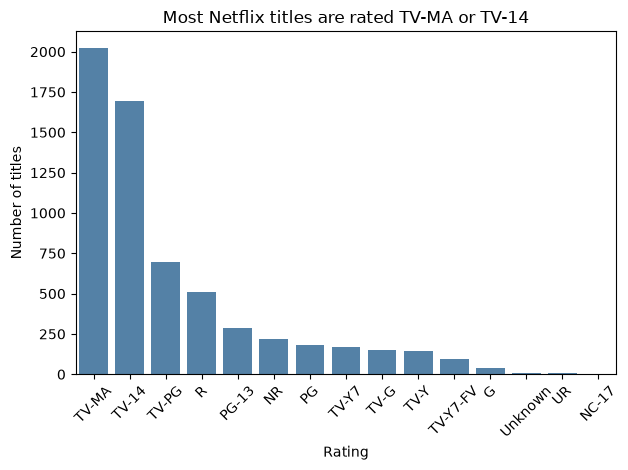

In [5]:
# Step 4a: Ratings distribution
order = df["rating"].value_counts().index     # biggest to smallest

sns.countplot(data=df, x="rating", order=order, color="steelblue")
plt.title("Most Netflix titles are rated TV-MA or TV-14")
plt.xlabel("Rating")
plt.ylabel("Number of titles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("ratings_distribution.png")      # save BEFORE show
plt.show()

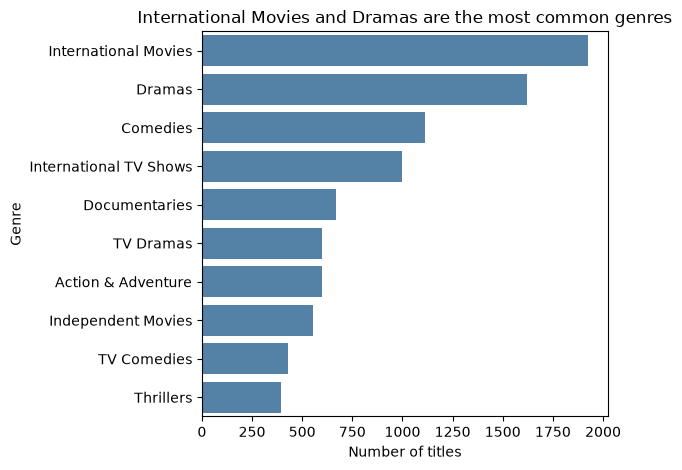

In [6]:
genres = df["listed_in"].str.split(", ").explode()
top_genres = genres.value_counts().head(10)

sns.barplot(x=top_genres.values, y=top_genres.index, color="steelblue")
plt.title("International Movies and Dramas are the most common genres")
plt.xlabel("Number of titles")
plt.ylabel("Genre")
plt.tight_layout()
plt.savefig("top_genres.png")
plt.show()